Arizona Air Quality

In [94]:
import pandas as pd

# Load the dataset
data = pd.read_csv('Daily+Particulate+Air+Quality.csv')
data.info()
print(data.describe())
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118080 entries, 0 to 118079
Data columns (total 13 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            118080 non-null  int64  
 1   Site.ID                               118080 non-null  int64  
 2   Date                                  118080 non-null  object 
 3   Daily.Mean.PM2.5.Concentration.ug.m3  40053 non-null   float64
 4   Daily.PM2.5.AQI.Value                 40053 non-null   float64
 5   Daily.Mean.PM10.Concentration.ug.m3   112249 non-null  float64
 6   Daily.PM10.AQI.Value                  112249 non-null  float64
 7   Site.Name                             118080 non-null  object 
 8   CBSA_NAME                             113234 non-null  object 
 9   COUNTY                                118080 non-null  object 
 10  SITE_LATITUDE                         118080 non-null  float64
 11  

,Unnamed: 0,Site.ID,Date,Daily.Mean.PM2.5.Concentration.ug.m3,Daily.PM2.5.AQI.Value,Daily.Mean.PM10.Concentration.ug.m3,Daily.PM10.AQI.Value,Site.Name,CBSA_NAME,COUNTY,SITE_LATITUDE,SITE_LONGITUDE,STATE
0,1,40011003,01/01/2017,NaN,NaN,3.0,3.0,White Mountain Fort Apache Reservation,NaN,Apache,34.07339,-109.85801,Arizona
1,2,40011003,08/21/2018,NaN,NaN,14.0,13.0,White Mountain Fort Apache Reservation,NaN,Apache,34.07339,-109.85801,Arizona
2,3,40011003,09/10/2019,NaN,NaN,9.0,8.0,White Mountain Fort Apache Reservation,NaN,Apache,34.07339,-109.85801,Arizona
3,4,40011003,04/11/2021,NaN,NaN,25.0,23.0,White Mountain Fort Apache Reservation,NaN,Apache,34.07339,-109.85801,Arizona
4,5,40011003,01/11/2018,NaN,NaN,5.0,5.0,White Mountain Fort Apache Reservation,NaN,Apache,34.07339,-109.85801,Arizona


Preprocessing

In [95]:

# Convert 'Date' to datetime
data['Date'] = pd.to_datetime(data['Date'], format='%m/%d/%Y')

# Drop columns with mostly NaN
#data.drop(['Daily.Mean.PM2.5.Concentration.ug.m3', 'Daily.PM2.5.AQI.Value'])

# Drop rows with NaN values in PM10 concentrations and AQI
data = data.dropna(subset=['Daily.Mean.PM2.5.Concentration.ug.m3', 'Daily.PM2.5.AQI.Value', 'Daily.Mean.PM10.Concentration.ug.m3', 'Daily.PM10.AQI.Value'])

# Rename columns for easier access
data.rename(columns={
    'Daily.Mean.PM2.5.Concentration.ug.m3': 'PM2.5 Concentration',
    'Daily.PM2.5.AQI.Value': 'PM2.5 AQI',
    'Daily.Mean.PM10.Concentration.ug.m3': 'PM10 Concentration',
    'Daily.PM10.AQI.Value': 'PM10 AQI'
}, inplace=True)
print(data.info())
data.head()

<class 'pandas.core.frame.DataFrame'>
Index: 34222 entries, 4879 to 118079
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Unnamed: 0           34222 non-null  int64         
 1   Site.ID              34222 non-null  int64         
 2   Date                 34222 non-null  datetime64[ns]
 3   PM2.5 Concentration  34222 non-null  float64       
 4   PM2.5 AQI            34222 non-null  float64       
 5   PM10 Concentration   34222 non-null  float64       
 6   PM10 AQI             34222 non-null  float64       
 7   Site.Name            34222 non-null  object        
 8   CBSA_NAME            32165 non-null  object        
 9   COUNTY               34222 non-null  object        
 10  SITE_LATITUDE        34222 non-null  float64       
 11  SITE_LONGITUDE       34222 non-null  float64       
 12  STATE                34222 non-null  object        
dtypes: datetime64[ns](1), float64(6)

,Unnamed: 0,Site.ID,Date,PM2.5 Concentration,PM2.5 AQI,PM10 Concentration,PM10 AQI,Site.Name,CBSA_NAME,COUNTY,SITE_LATITUDE,SITE_LONGITUDE,STATE
4879,4880,40031005,2017-07-28,3.1,13.0,7.0,6.0,DOUGLAS RED CROSS,"Sierra Vista-Douglas, AZ",Cochise,31.3492,-109.539683,Arizona
4880,4881,40031005,2017-07-18,3.9,16.0,9.0,8.0,DOUGLAS RED CROSS,"Sierra Vista-Douglas, AZ",Cochise,31.3492,-109.539683,Arizona
4881,4882,40031005,2019-01-07,4.9,20.0,23.0,21.0,DOUGLAS RED CROSS,"Sierra Vista-Douglas, AZ",Cochise,31.3492,-109.539683,Arizona
4882,4883,40031005,2018-11-24,4.5,19.0,39.0,36.0,DOUGLAS RED CROSS,"Sierra Vista-Douglas, AZ",Cochise,31.3492,-109.539683,Arizona
4885,4886,40031005,2017-09-02,8.7,36.0,32.0,30.0,DOUGLAS RED CROSS,"Sierra Vista-Douglas, AZ",Cochise,31.3492,-109.539683,Arizona


Thresholds

In [96]:
# Define good air quality thresholds
good_pm25_threshold = 12  # in µg/m³
good_pm10_threshold = 50   # in µg/m³
good_pm25_aqi_threshold = 50
good_pm10_aqi_threshold = 50
# Create a new column to classify air quality
data['Air Quality'] = 'Good'
data.loc[(data['PM2.5 Concentration'] > good_pm25_threshold) | (data['PM10 Concentration'] > good_pm10_threshold) | (data['PM2.5 AQI'] > good_pm25_aqi_threshold) | (data['PM10 AQI'] > good_pm10_aqi_threshold), 'Air Quality'] = 'Poor'


Visualisation

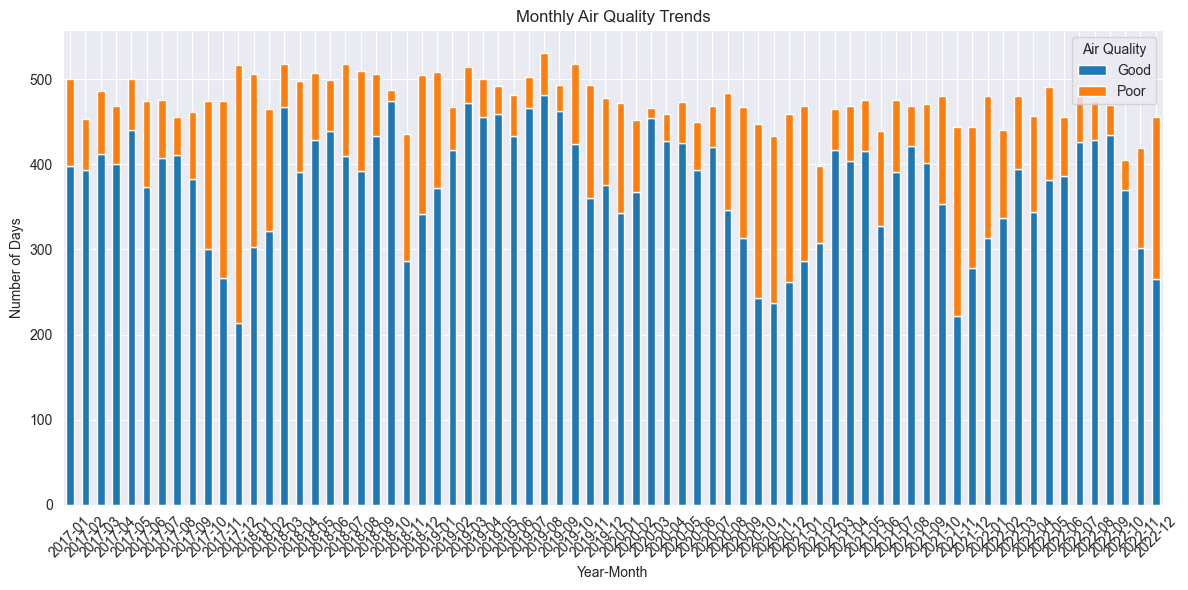

In [97]:
import matplotlib.pyplot as plt

# Group by month and year to analyze seasonal trends
data['YearMonth'] = data['Date'].dt.to_period('M')
monthly_data = data.groupby(['YearMonth', 'Air Quality']).size().unstack(fill_value=0)

# Plotting
monthly_data.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Monthly Air Quality Trends')
plt.xlabel('Year-Month')
plt.ylabel('Number of Days')
plt.xticks(rotation=45)
plt.legend(title='Air Quality')
plt.tight_layout()
plt.show()


Group by seasons

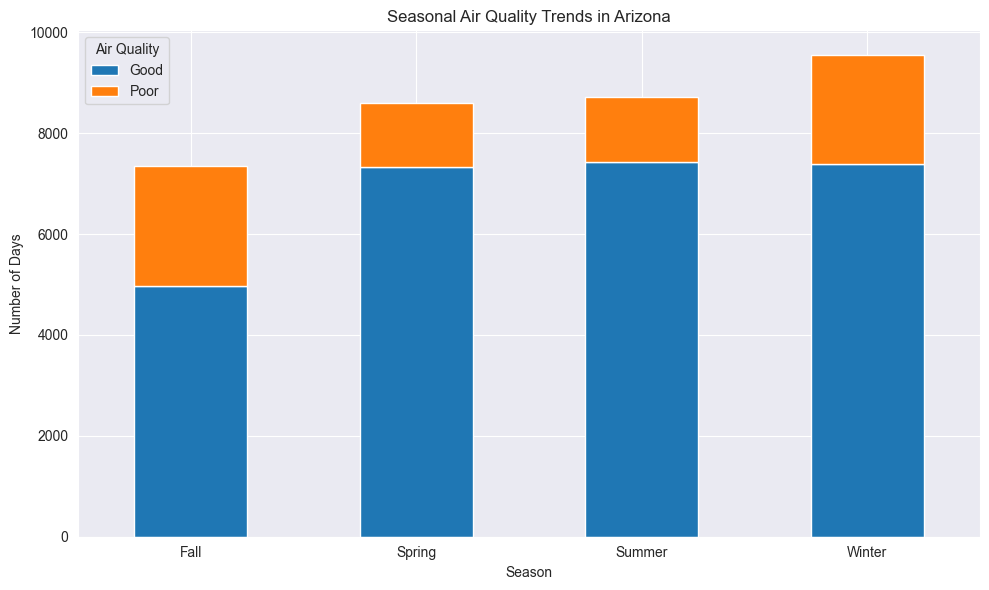

In [98]:
def assign_season(date):
    if (date.month == 12 and date.day >= 21) or (date.month <= 3) or (date.month == 3 and date.day <= 20):
        return 'Winter'
    elif (date.month == 3 and date.day >= 21) or (date.month <= 6 and date.month != 3) or (date.month == 6 and date.day <= 20):
        return 'Spring'
    elif (date.month == 6 and date.day >= 21) or (date.month <= 9 and date.month != 6) or (date.month == 9 and date.day <= 22):
        return 'Summer'
    else:
        return 'Fall'

data['Season'] = data['Date'].apply(assign_season)
seasonal_data = data.groupby(['Season', 'Air Quality']).size().unstack(fill_value=0)
import matplotlib.pyplot as plt

# Plotting seasonal air quality data
seasonal_data.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Seasonal Air Quality Trends in Arizona')
plt.xlabel('Season')
plt.ylabel('Number of Days')
plt.xticks(rotation=0)
plt.legend(title='Air Quality')
plt.tight_layout()
plt.show()


KPI

In [99]:
# Calculate average PM2.5 and PM10 for each season
avg_pm25 = data.groupby('Season')['PM2.5 Concentration'].mean()
avg_pm10 = data.groupby('Season')['PM10 Concentration'].mean()
print(avg_pm25.head())
avg_pm10.head()

Season
Fall      9.566195
Spring    7.335789
Summer    7.111344
Winter    8.502353
Name: PM2.5 Concentration, dtype: float64


Season
Fall      38.540199
Spring    33.772114
Summer    31.630764
Winter    28.389185
Name: PM10 Concentration, dtype: float64

In [100]:
# Create speedometer gauges for PM2.5 and PM10
fig_pm25 = go.Figure()
fig_pm10 = go.Figure()

seasons = ['Fall', 'Spring', 'Summer', 'Winter']
pm25_values = avg_pm25.values
pm10_values = avg_pm10.values

# Create PM2.5 gauges
for i, season in enumerate(seasons):
    if season in ['Spring', 'Summer']:
        row = 0
        column = i % 2
    else:
        row = 2
        column = (i+1)%2
    fig_pm25.add_trace(go.Indicator(
        mode="gauge+number",
        value=pm25_values[i],
        title={'text': f"Avg PM2.5 ({season})"},
        gauge={
            'axis': {'range': [0, 50]},  
            'bar': {'color': "orange"},
            'steps': [
                {'range': [0, 8], 'color': "teal"},
                {'range': [8, 30], 'color': "yellow"},
                {'range': [30, 50], 'color': "red"},
            ],
        },
        domain={'row': row, 'column': column}
    ))

# Create PM10 gauges
for i, season in enumerate(seasons):
    if season in ['Spring', 'Summer']:
        row = 0
        column = i % 2
    else:
        row = 2
        column = (i+1)%2
    fig_pm10.add_trace(go.Indicator(
        mode="gauge+number",
        value=pm10_values[i],
        title={'text': f"Avg PM10 ({season})"},
        gauge={
            'axis': {'range': [0, 150]}, 
            'bar': {'color': "orange"},
            'steps': [
                {'range': [0, 35], 'color': "teal"},
                {'range': [35, 80], 'color': "yellow"},
                {'range': [80, 150], 'color': "red"},
            ],
        },
        domain={'row': row, 'column': column}
    ))

# Update layout for PM2.5
fig_pm25.update_layout(
    grid={'rows': 3, 'columns': 2},
)

# Update layout for PM10
fig_pm10.update_layout(
    grid={'rows': 3, 'columns': 2},
)

# Show the figures
fig_pm25.show()
fig_pm10.show()


Battery visualisation

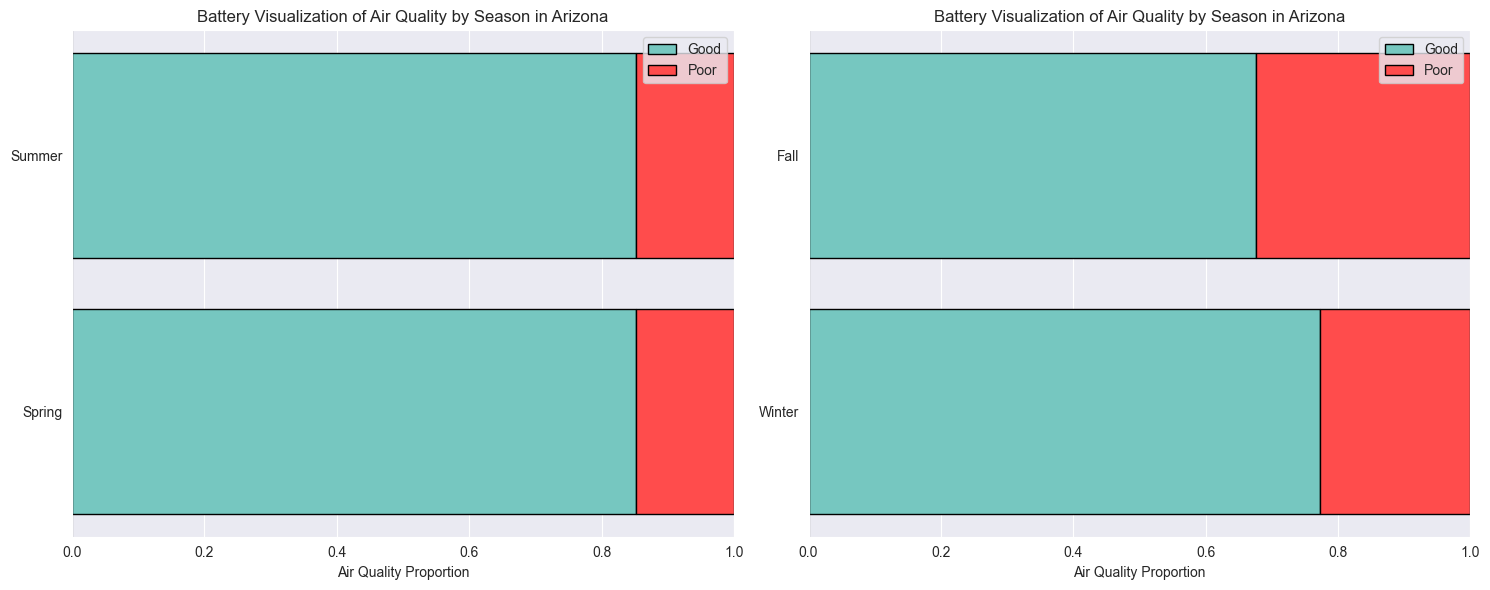

In [101]:
# Create a figure for battery visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Define battery properties
battery_width = 0.3
battery_height = 0.8

# Define colors for Good and Poor air quality
colors = ['#76c7c0', '#ff4c4c']  # Good: teal, Poor: red

# Create battery bars for each season
for i, season in enumerate(['Spring', 'Summer']):
    good_days = seasonal_data.loc[season, 'Good']
    poor_days = seasonal_data.loc[season, 'Poor']
    
    # Calculate proportions
    total_days = good_days + poor_days
    good_ratio = good_days / total_days if total_days > 0 else 0
    poor_ratio = poor_days / total_days if total_days > 0 else 0
    
    # Create battery representation
    ax1.barh(season, good_ratio, color=colors[0], edgecolor='black', height=battery_height, label='Good' if i == 0 else "")
    ax1.barh(season, poor_ratio, color=colors[1], edgecolor='black', height=battery_height, left=good_ratio, label='Poor' if i == 0 else "")

for i, season in enumerate(['Winter', 'Fall']):
    good_days = seasonal_data.loc[season, 'Good']
    poor_days = seasonal_data.loc[season, 'Poor']

    # Calculate proportions
    total_days = good_days + poor_days
    good_ratio = good_days / total_days if total_days > 0 else 0
    poor_ratio = poor_days / total_days if total_days > 0 else 0

    # Create battery representation
    ax2.barh(season, good_ratio, color=colors[0], edgecolor='black', height=battery_height, label='Good' if i == 0 else "")
    ax2.barh(season, poor_ratio, color=colors[1], edgecolor='black', height=battery_height, left=good_ratio, label='Poor' if i == 0 else "")

# Set limits and labels
ax1.set_xlim(0, 1)
ax1.set_xlabel('Air Quality Proportion')
ax1.set_title('Battery Visualization of Air Quality by Season in Arizona')
ax1.axvline(0, color='black', linewidth=0.8)  # Center line
ax1.legend(loc='upper right')

ax2.set_xlim(0, 1)
ax2.set_xlabel('Air Quality Proportion')
ax2.set_title('Battery Visualization of Air Quality by Season in Arizona')
ax2.axvline(0, color='black', linewidth=0.8)  # Center line
ax2.legend(loc='upper right')

# Show the plot
plt.tight_layout()
plt.show()
